# Домашнє завдання: Побудова класифікатора сентименту на основі набору даних Tweet Sentiment Extraction

**Мета:** Провести аналіз набору даних, виконати векторизацію текстових даних за допомогою методів bag-of-words та TF-IDF, порівняти їх, побудувати класифікатор та провести аналіз помилок.

**Набір даних:**
Дані беремо з цього змагання на Kaggle: https://www.kaggle.com/competitions/tweet-sentiment-extraction/data?select=train.csv


Якщо не вдається завантажиит з Kaggle, ось тут можна - https://drive.google.com/file/d/1kfu5zCRsDHxoBZigBlGIcCieKlws02HT/view?usp=sharing

Оригінальне змагання має дещо іншу задачу, але ми будемо поки будувати саме класифікатор.

Увага! В цьому наборі завдань для простоти експериментів ми будемо спочатку робити векторизацію на всьому наборі даних, а потім розбивку на train i test. В робочих проєктах ми теж можемо використати цей підхід для швидшої побудови PoC (proof of concept). Але фінальне рішення, яке ми будемо деплоїти - треба проводити за правилом - спочатку розбивка на трейн і тест, потім пишемо обробку для трейну, навчаємо векторизатори. І потім використовуємо готові векторизатори для тесту і всіх даних на етапі передбачення (інференсу).

### Завдання 1. Завантаження та ознайомлення з набором даних

- Завантажте набір даних `train.csv` з посилання та ознайомтеся з його структурою.
- Виведіть перші 5 рядків та основну статистику: кількість записів, типи колонок, кількість пропущених значень.
- Видаліть записи, в яких є пропущені значення.



In [1]:
import pandas as pd

train_fname = 'tweet_sentiment_train.csv.zip'
raw_df = pd.read_csv(train_fname)

raw_df.head()

,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


In [2]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27481 entries, 0 to 27480
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   textID         27481 non-null  object
 1   text           27480 non-null  object
 2   selected_text  27480 non-null  object
 3   sentiment      27481 non-null  object
dtypes: object(4)
memory usage: 858.9+ KB


In [3]:
raw_df.dropna(inplace=True)
raw_df.isna().sum()

textID           0
text             0
selected_text    0
sentiment        0
dtype: int64

### Завдання 2. Exploratory Data Analysis

- Проведіть аналіз кількості класів та розподілу міток. Класи знаходяться в колонці `sentiment`.
- Візуалізуйте розподіл довжин текстів в символах та зробіть висновок про довжини постів: якої довжини постів найбільше, що бачите з розподілу?



In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

Кількість унікальних класів: 3

Розподіл міток (кількість):
sentiment
neutral     11117
positive     8582
negative     7781
Name: count, dtype: int64

Розподіл міток (%):
sentiment
neutral     40.45
positive    31.23
negative    28.32
Name: proportion, dtype: float64


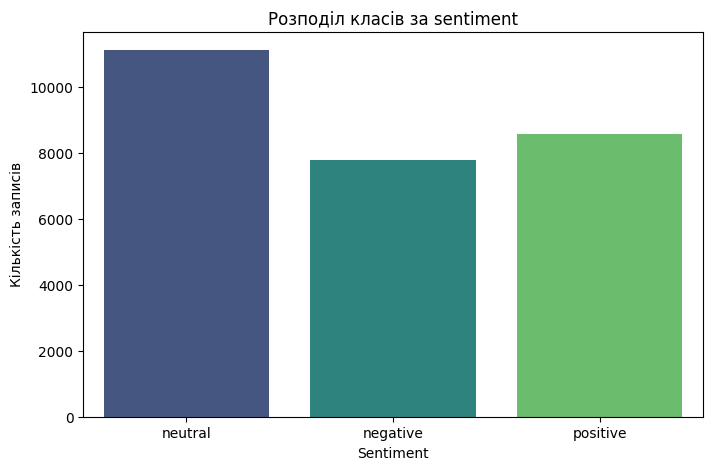

In [5]:
print(f"Кількість унікальних класів: {raw_df['sentiment'].nunique()}")
print("\nРозподіл міток (кількість):")
print(raw_df['sentiment'].value_counts())

print("\nРозподіл міток (%):")
print(raw_df['sentiment'].value_counts(normalize=True).round(4) * 100)

plt.figure(figsize=(8, 5))
sns.countplot(data=raw_df, x='sentiment', palette='viridis', hue='sentiment')
plt.title('Розподіл класів за sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Кількість записів')
plt.show()

count    27480.000000
mean        68.330022
std         35.603870
min          3.000000
25%         39.000000
50%         64.000000
75%         97.000000
max        141.000000
Name: text_length, dtype: float64


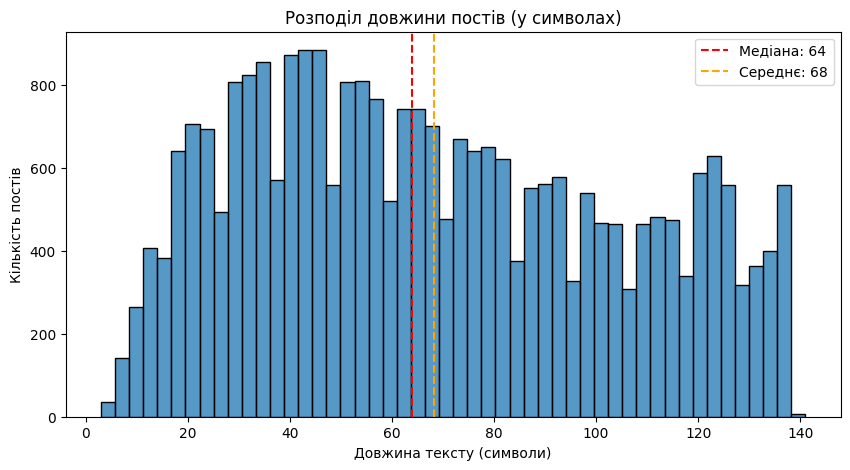

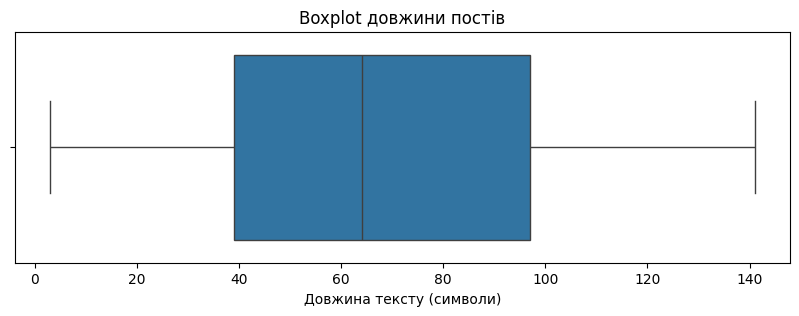

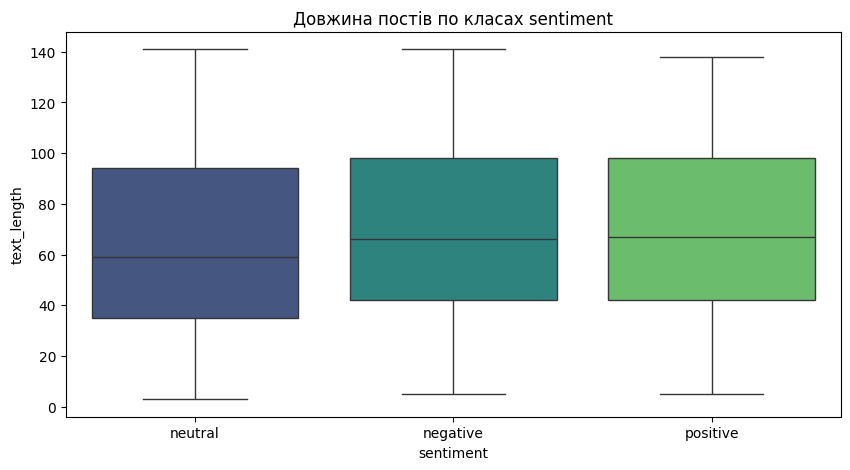

In [6]:
raw_df['text_length'] = raw_df['text'].astype(str).apply(len)

# Описова статистика
print(raw_df['text_length'].describe())

# Гістограма розподілу довжин
plt.figure(figsize=(10, 5))
sns.histplot(raw_df['text_length'], bins=50)
plt.title('Розподіл довжини постів (у символах)')
plt.xlabel('Довжина тексту (символи)')
plt.ylabel('Кількість постів')
plt.axvline(raw_df['text_length'].median(), color='red', linestyle='--', label=f"Медіана: {raw_df['text_length'].median():.0f}")
plt.axvline(raw_df['text_length'].mean(), color='orange', linestyle='--', label=f"Середнє: {raw_df['text_length'].mean():.0f}")
plt.legend()
plt.show()

plt.figure(figsize=(10, 3))
sns.boxplot(x=raw_df['text_length'])
plt.title('Boxplot довжини постів')
plt.xlabel('Довжина тексту (символи)')
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=raw_df, x='sentiment', y='text_length', palette='viridis', hue='sentiment')
plt.title('Довжина постів по класах sentiment')
plt.show()

### Завдання 3. Попередня обробка текстових даних та векторизація з bag of words


Наша задача тут отримати вектори методом bag of words колонки `text`, виконавши попередню обробку тексту.
Попередня обробка має включати
- видалення stopwords необхідної мови
- токенізація (розбиття текстів на фрагменти по 1 слову)
- стеммінг слів зі `SnowballStemmer`.
- самостійно задайте кількість слів в словнику для `sklearn.feature_extraction.text.CountVectorizer`. Можливо для цього доведеться виконати додатковий аналіз.

Ви також можете додати сюди додаткові методи очистки текстів, наприклад, видалення деяких символів чи груп символів, якщо в процесі роботи побачите, що хочете щось видалити.

Напишіть код аби виконати це завдання. Перед цим рекомендую детально ознайомитись з тим, що робить обʼєкт `sklearn.feature_extraction.text.CountVectorizer` за замовченням.

Це завдання можна виконати двома способами - один - максимально подібно до того, як ми це робили в лекції, другий - дещо інакше перегрупувавши етапи обробки тексту.




In [7]:
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer

nltk.download('stopwords')
nltk.download('punkt')

stop_words = set(stopwords.words('english'))
stemmer = SnowballStemmer('english')

[nltk_data] Downloading package stopwords to /Users/mavka/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /Users/mavka/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [8]:
def preprocess_text(text):
    text = str(text).lower()

    # очищення тексту
    text = re.sub(r'http\S+|www\.\S+', '', text) # URL
    text = re.sub(r'@\w+', '', text) # згадки (@user)
    text = re.sub(r'#', '', text) # хештег-символи
    text = re.sub(r'&\w+;', '', text) # HTML-сутності на кшталт &amp;
    text = re.sub(r"['`’]", '', text)          # didn't -> didnt, wasn`t -> wasnt
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)   # решта пунктуації -> пробіл
    text = re.sub(r'\s+', ' ', text).strip() # зайві пробіли
    # після першого результату векторизації помітила слова ahhhhh alllll і вирішила теж додати в пропроцесинг
    # Три й більше однакових літер поспіль -> дві
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    # Токенізація
    tokens = word_tokenize(text)
    
    # Видалення stopwords + занадто коротких "слів" (залишки у 1 символ)
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    
    # Стеммінг
    tokens = [stemmer.stem(t) for t in tokens]

    # після першого результату векторизації помітила, що попереднього фіксу не достатньо і все ще
    # залишалось багато слів типу hahaha, aww, umm ...
    interjection_pattern = re.compile(r'^(a+h+|h+a+(h+a*)*|o+h+|u+h+|u+m+|h+m+|a+w+|e+w+)$')
    tokens = [t for t in tokens if not interjection_pattern.match(t)]
    
    return ' '.join(tokens)

raw_df['text_clean'] = raw_df['text'].apply(preprocess_text)
raw_df[['text', 'text_clean']].head(10)

,text,text_clean
0,"I`d have responded, if I were going",id respond go
1,Sooo SAD I will miss you here in San Diego!!!,soo sad miss san diego
2,my boss is bullying me...,boss bulli
3,what interview! leave me alone,interview leav alon
4,"Sons of ****, why couldn`t they put them on t...",son couldnt put releas alreadi bought
5,http://www.dothebouncy.com/smf - some shameles...,shameless plug best ranger forum earth
6,2am feedings for the baby are fun when he is a...,feed babi fun smile coo
7,Soooo high,soo high
8,Both of you,
9,Journey!? Wow... u just became cooler. hehe....,journey wow becam cooler hehe possibl


Повний розмір словника: 17919
Частота кожного слова в корпусі
        word  count
7532      im   3109
3822     day   2492
6301      go   2384
6147     get   1917
6344    good   1624
...      ...    ...
9141    long    308
14391   soon    307
17703    yes    306
16600    use    302
9037   littl    300

[100 rows x 2 columns]


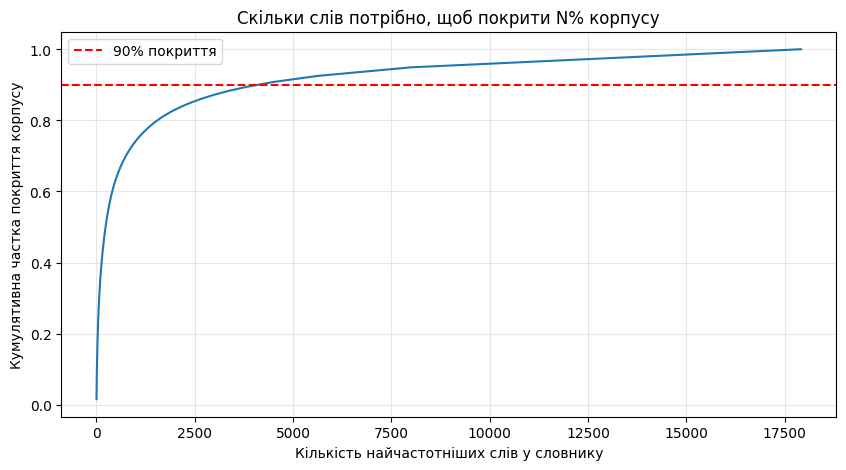

Слів потрібно для покриття 90% корпусу: 4099


In [9]:
vectorizer_full = CountVectorizer()
X_full = vectorizer_full.fit_transform(raw_df['text_clean'])

print(f"Повний розмір словника: {len(vectorizer_full.vocabulary_)}")

print("Частота кожного слова в корпусі")
word_freq = pd.DataFrame({
    'word': vectorizer_full.get_feature_names_out(),
    'count': X_full.sum(axis=0).A1
}).sort_values('count', ascending=False)

print(word_freq.head(100))

word_freq['cumulative_pct'] = word_freq['count'].cumsum() / word_freq['count'].sum()
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(word_freq) + 1), word_freq['cumulative_pct'])
plt.xlabel('Кількість найчастотніших слів у словнику')
plt.ylabel('Кумулятивна частка покриття корпусу')
plt.title('Скільки слів потрібно, щоб покрити N% корпусу')
plt.axhline(0.9, color='red', linestyle='--', label='90% покриття')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

n_words_90 = (word_freq['cumulative_pct'] <= 0.9).sum()
print(f"Слів потрібно для покриття 90% корпусу: {n_words_90}")

In [10]:
VOCAB_SIZE = n_words_90

vectorizer = CountVectorizer(
    max_features=VOCAB_SIZE,
    min_df=2,
    max_df=0.95
)

X_bow = vectorizer.fit_transform(raw_df['text_clean'])

print(f"Форма матриці Bag of Words: {X_bow.shape}")
print(f"Приклад слів у словнику: {vectorizer.get_feature_names_out()[:100]}")

Форма матриці Bag of Words: (27480, 4099)
Приклад слів у словнику: ['aa' 'aaron' 'ab' 'abandon' 'abbi' 'abil' 'abit' 'abl' 'absolut' 'abt'
 'ac' 'academi' 'accept' 'access' 'accid' 'accident' 'accomplish' 'accord'
 'account' 'acct' 'ace' 'ach' 'achiev' 'ack' 'across' 'act' 'action'
 'activ' 'actor' 'actress' 'actual' 'ad' 'adam' 'add' 'addict' 'address'
 'admir' 'admit' 'adopt' 'ador' 'adult' 'advanc' 'advantag' 'adventur'
 'advert' 'advic' 'affect' 'afford' 'afraid' 'afternoon' 'afterward' 'age'
 'agh' 'ago' 'agre' 'aha' 'ahaha' 'ahahaha' 'ahead' 'aight' 'aim' 'aint'
 'air' 'airport' 'aka' 'ako' 'al' 'ala' 'alarm' 'alaska' 'album' 'alcohol'
 'alex' 'alexi' 'algebra' 'ali' 'alic' 'alien' 'aliv' 'allah' 'allen'
 'allerg' 'allergi' 'allow' 'almost' 'alon' 'along' 'alot' 'alreadi'
 'alright' 'also' 'altern' 'although' 'alway' 'amaz' 'amazon' 'amber'
 'america' 'american' 'ami']


Після попередньої обробки тексту та токенізації отримали словник розміром 17919, проте після аналізу кукулятивного покриття було виявлено, що перші 4099 слів достатньо для того або покрити 90% вживань в корпусі. Тому для countVectorizer я взяла це число. Із іншиї параметрів - відфільтрувала слова, що зустрічаються менш, ніж у 2 документах (min_df=2), і дуже загальні слова, присутні більш ніж у 95% документів (max_df=0.95)."

### Завдання 4. Побудова класифікатора

- Розділіть індекси даних на навчальний та тестовий набори в обраному співвівдношенні. Використовуючи отримані індекси сфомуйте набори для тренування класифікатора `X_train_bow, X_test_bow, y_train, y_test`.
- Навчіть класифікатор (наприклад, Logistic Regression, Decision Tree або один з алгоритмів бустингу) на даних, векторизованих методом bag-of-words. Спробуйте кілька моделей і оберіть найбільш точну :)
- Виведіть інформацію, яка дає можливість оцінити якість класифікації.
- Оцініть якість фінальної класифікації: вона хороша чи не дуже?



In [11]:
import numpy as np
from sklearn.model_selection import train_test_split

indices = np.arange(len(raw_df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=10,
    stratify=raw_df['sentiment']
)

X_train_bow = X_bow[train_idx]
X_test_bow = X_bow[test_idx]
y_train = raw_df['sentiment'].iloc[train_idx]
y_test = raw_df['sentiment'].iloc[test_idx]

print(X_train_bow.shape, X_test_bow.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

(21984, 4099) (5496, 4099)
sentiment
neutral     0.405
positive    0.312
negative    0.283
Name: proportion, dtype: float64
sentiment
neutral     0.404
positive    0.312
negative    0.283
Name: proportion, dtype: float64


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=500, random_state=10),
    'Linear SVC': LinearSVC(random_state=10),
    'Decision Tree': DecisionTreeClassifier(max_depth=20, random_state=10),
    'Random Forest': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=10),
}

results = []
fitted = {}
for name, model in models.items():
    model.fit(X_train_bow, y_train)
    pred = model.predict(X_test_bow)
    fitted[name] = model
    results.append({
        'model': name,
        'train_acc': accuracy_score(y_train, model.predict(X_train_bow)),
        'test_acc': accuracy_score(y_test, pred),
        'test_f1_macro': f1_score(y_test, pred, average='macro'),
    })

results_df = pd.DataFrame(results).sort_values('test_f1_macro', ascending=False).round(4)
results_df

,model,train_acc,test_acc,test_f1_macro
3,Random Forest,0.9927,0.7003,0.7000
0,Logistic Regression,0.8096,0.6912,0.6916
1,Linear SVC,0.8217,0.6689,0.6697
2,Decision Tree,0.6605,0.6130,0.5821


Random Forest - дуже перенавчена модель, але яка все ж дає накращу точність
Logistic Regression - теж оверфіт, але не такий великий
linear SVC  - більший оверфіт, ніж для логістичної регресії і гірший результат на тестових даних
decision tree - незначний оверфіт, але найгірший результат по точності

Мій вибір - логістична регресія, точність її майже така ж, як і в random forest, проте не настільки перенавчена

              precision    recall  f1-score   support

    negative       0.70      0.62      0.66      1556
     neutral       0.64      0.72      0.68      2223
    positive       0.76      0.71      0.73      1717

    accuracy                           0.69      5496
   macro avg       0.70      0.69      0.69      5496
weighted avg       0.70      0.69      0.69      5496



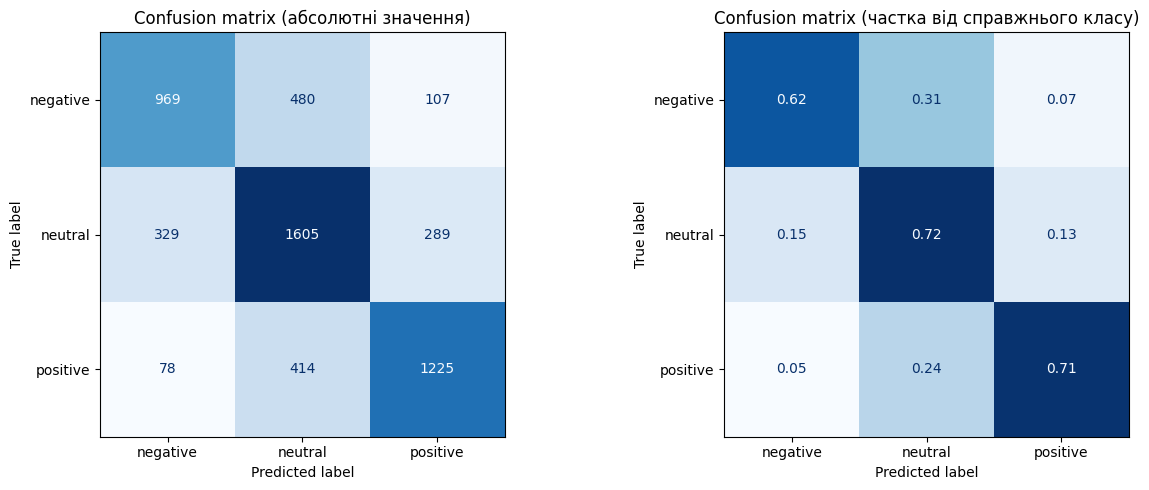

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_model = models['Logistic Regression']
y_pred = best_model.predict(X_test_bow)

print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion matrix (абсолютні значення)')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[1], cmap='Blues',
                                        normalize='true', values_format='.2f', colorbar=False)
axes[1].set_title('Confusion matrix (частка від справжнього класу)')
plt.tight_layout()
plt.show()

як не мене, результати досить хороші, і плюс мінус однакові для всіх класів (з урахуванням їх частоти в початковому наборі)

### Завдання 5. Аналіз впливовості слів в отриманого класифікатора

- Для обраної вами моделі проведіть аналіз важливості слів (ознак): які слова (токени) найбільше впливають для визначення сентименту? Чи це логічно на ваш погляд, що саме ці символи впливають найбільше/найменще?


In [14]:
feature_names = vectorizer.get_feature_names_out()
classes = best_model.classes_
coefs = best_model.coef_

# Скільки разів кожне слово зустрічається в тренувальних даних
train_counts = np.asarray(X_train_bow.sum(axis=0)).ravel()

def top_words(weights, n=15):
    order = np.argsort(weights)
    return order[:n], order[-n:][::-1]

for i, cls in enumerate(classes):
        _, top_idx = top_words(coefs[i])
        print(f'Клас "{cls}":')
        print(pd.DataFrame({'word': feature_names[top_idx], 'coef': coefs[i][top_idx].round(2),
                            'count': train_counts[top_idx]}), '\n')

Клас "negative":
          word  coef  count
0          sad  2.84    435
1         suck  2.61    237
2         bore  2.35    183
3        sorri  2.34    411
4         hate  2.33    303
5         miss  2.18    794
6         fail  2.15    100
7      exhaust  2.03     25
8        shame  2.01     38
9        worst  2.01     38
10        sick  1.98    206
11    unfortun  1.97     46
12         wtf  1.95     47
13        poor  1.94    137
14  disappoint  1.93     38 

Клас "neutral":
           word  coef  count
0   starwarsday  1.61      6
1      otherwis  1.52     13
2        indoor  1.52      5
3        resist  1.25      7
4          chan  1.24      4
5         logic  1.19     11
6          yell  1.18      9
7            sp  1.18      7
8           jst  1.18      7
9            lo  1.18      6
10          wud  1.14      6
11         dive  1.12      5
12           ed  1.09     11
13          ian  1.09      5
14         moro  1.08     13 

Клас "positive":
         word  coef  count
0      

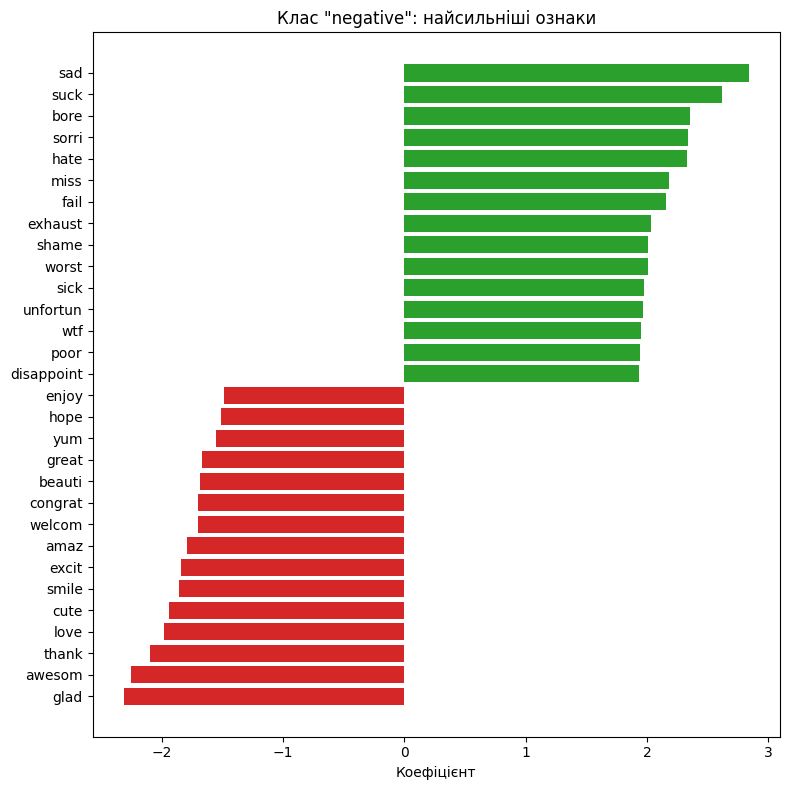

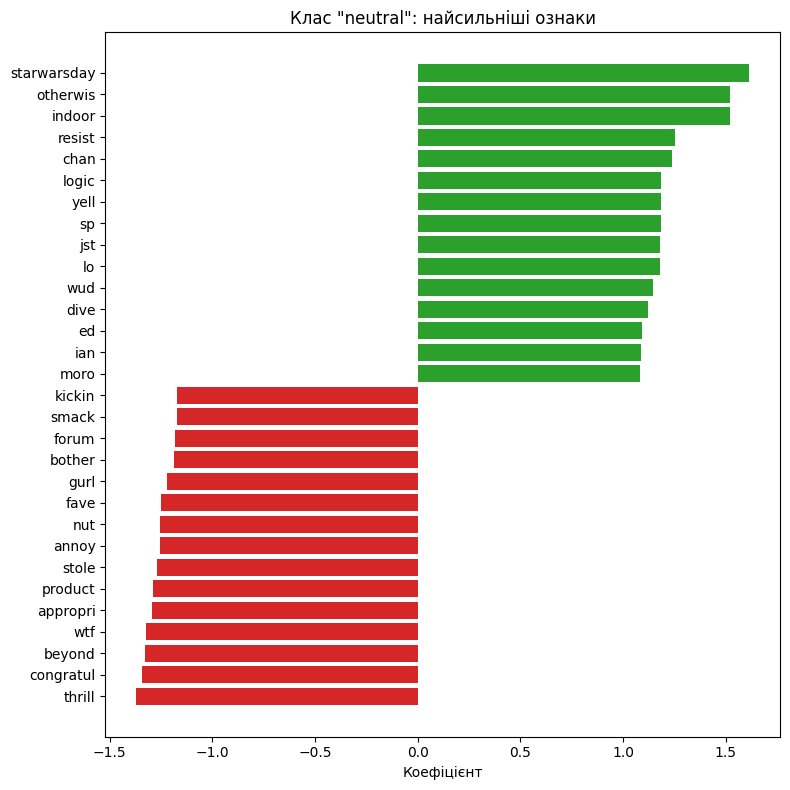

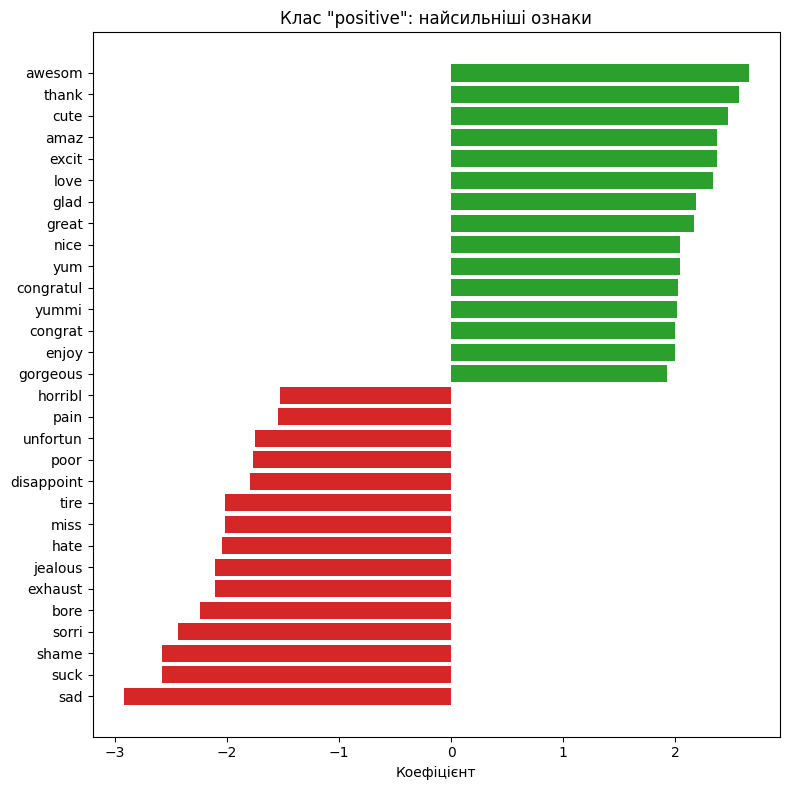

In [15]:
def plot_top(coef_row, title, n=15):
    order = np.argsort(coef_row)
    idx = np.concatenate([order[:n], order[-n:]])
    colors = ['tab:red' if coef_row[i] < 0 else 'tab:green' for i in idx]
    plt.figure(figsize=(8, 8))
    plt.barh(feature_names[idx], coef_row[idx], color=colors)
    plt.title(title)
    plt.xlabel('Коефіцієнт')
    plt.tight_layout()
    plt.show()

for i, cls in enumerate(classes):
    plot_top(coefs[i], f'Клас "{cls}": найсильніші ознаки')

In [16]:
importance = np.abs(coefs).mean(axis=0)

# беремо тільки слова, які зустрічаються досить часто, інакше «неважливими» будуть просто рідкісні
frequent = train_counts >= 50
least_idx = np.where(frequent)[0][np.argsort(importance[frequent])[:20]]

print('Часті слова з найменшим впливом:')
print(pd.DataFrame({'word': feature_names[least_idx],
                    'importance': importance[least_idx].round(4),
                    'count': train_counts[least_idx]}))

Часті слова з найменшим впливом:
     word  importance  count
0     eye      0.0128     80
1     say      0.0168    423
2   could      0.0263    320
3    last      0.0313    489
4    need      0.0334    568
5    must      0.0337    126
6    quit      0.0347     98
7    live      0.0404    218
8    movi      0.0424    245
9    girl      0.0424    233
10     pm      0.0431     66
11   your      0.0443    281
12   song      0.0444    185
13    bed      0.0446    305
14  guess      0.0467    174
15   went      0.0470    170
16    use      0.0470    251
17   book      0.0476    128
18  readi      0.0477    175
19  start      0.0488    310


Не маю змоги проаналізувати все детально, але переважно все виглядає досить логічно: сумні і з негативним забарвленням слова більш впливові для negative класу, і навпаки для positive класу. Значущі слова для neutral, як і неважливі слова - це більше нейтральні за забарвленням слова

### Завдання 6. Векторизація текстів з допомогою TF-IDF. Тренування класифікатора, аналіз точності і впливовості слів.

- Проведіть векторизацію текстів з векторизатором TfidfVectorizer. Реалізуйте векторизацію так, аби препроцесинг включав всі ті самі кроки, що і в випадку використання векторизації Bag of Words.

- Натренуйте той самий класифікатор на TF-IDF векторах, виконавши розбивку набору даних на train, test так, аби в трейні були всі ті самі записи, що і були в попередньому завданні (це важливо для порівняння результатів).

- Проаналізуйте якість класифікації вивівши потрібні для цього метрики. Чи стала якість класифікації кращою?

- Які токени найбільше впливають на результат при тренуваннні класифікатора з TF-IDF векторами? Порівняйте з найважливішими токенами при Bag of Words векторизації. Яку векторизацію ви б обрали для фінальної імплементації рішення? Обґрунтуйте свій вибір.



In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=VOCAB_SIZE,
    min_df=2,
    max_df=0.95
)

# text_clean уже пройшов весь препроцесинг
X_tfidf = tfidf_vectorizer.fit_transform(raw_df['text_clean'])

X_train_tfidf = X_tfidf[train_idx]
X_test_tfidf = X_tfidf[test_idx]
# y_train, y_test залишаємо та самі

print(X_tfidf.shape, X_bow.shape)

(27480, 4099) (27480, 4099)


In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# додамо ще тюнінг сюди
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}

def fit_and_eval(X_tr, X_te, name):
    grid = GridSearchCV(LogisticRegression(max_iter=2000, random_state=42),
                        param_grid, scoring='f1_macro', cv=5, n_jobs=-1)
    grid.fit(X_tr, y_train)
    model = grid.best_estimator_
    pred = model.predict(X_te)
    return model, pred, {
        'vectorizer': name,
        'best_C': grid.best_params_['C'],
        'cv_f1_macro': round(grid.best_score_, 4),
        'train_acc': round(accuracy_score(y_train, model.predict(X_tr)), 4),
        'test_acc': round(accuracy_score(y_test, pred), 4),
        'test_f1_macro': round(f1_score(y_test, pred, average='macro'), 4),
    }

lr_bow, pred_bow, res_bow = fit_and_eval(X_train_bow, X_test_bow, 'BoW')
lr_tfidf, pred_tfidf, res_tfidf = fit_and_eval(X_train_tfidf, X_test_tfidf, 'TF-IDF')

comparison = pd.DataFrame([res_bow, res_tfidf])
display(comparison)

print('=== BoW ===')
print(classification_report(y_test, pred_bow))
print('=== TF-IDF ===')
print(classification_report(y_test, pred_tfidf))

,vectorizer,best_C,cv_f1_macro,train_acc,test_acc,test_f1_macro
0,BoW,1,0.6879,0.8096,0.6912,0.6916
1,TF-IDF,1,0.6920,0.7746,0.6900,0.6892


=== BoW ===
              precision    recall  f1-score   support

    negative       0.70      0.62      0.66      1556
     neutral       0.64      0.72      0.68      2223
    positive       0.76      0.71      0.73      1717

    accuracy                           0.69      5496
   macro avg       0.70      0.69      0.69      5496
weighted avg       0.70      0.69      0.69      5496

=== TF-IDF ===
              precision    recall  f1-score   support

    negative       0.72      0.60      0.66      1556
     neutral       0.63      0.76      0.69      2223
    positive       0.77      0.68      0.72      1717

    accuracy                           0.69      5496
   macro avg       0.71      0.68      0.69      5496
weighted avg       0.70      0.69      0.69      5496



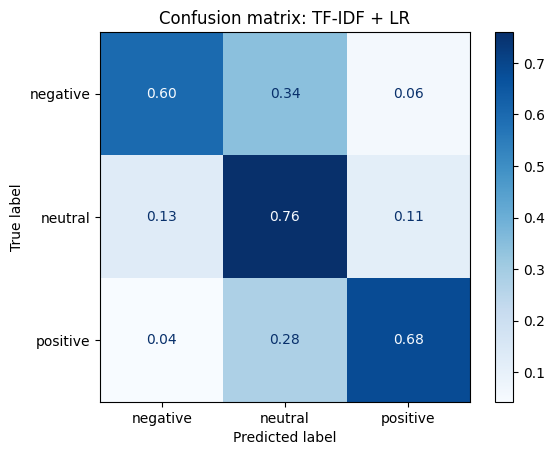

In [19]:
ConfusionMatrixDisplay.from_predictions(y_test, pred_tfidf, cmap='Blues', normalize='true', values_format='.2f')
plt.title('Confusion matrix: TF-IDF + LR')
plt.show()

In [20]:
feat_bow = vectorizer.get_feature_names_out()
feat_tfidf = tfidf_vectorizer.get_feature_names_out()

def top_tokens(model, feats, n=20):
    return {cls: list(feats[np.argsort(model.coef_[i])[-n:]][::-1])
            for i, cls in enumerate(model.classes_)}

top_bow = top_tokens(lr_bow, feat_bow)
top_tfidf = top_tokens(lr_tfidf, feat_tfidf)

for cls in top_bow:
    b, t = set(top_bow[cls]), set(top_tfidf[cls])
    print(f'\nКлас "{cls}"')
    print('  BoW:   ', top_bow[cls])
    print('  TF-IDF:', top_tfidf[cls])
    print(f'  Спільних токенів: {len(b & t)} з {len(b)} -> {sorted(b & t)}')
    print('  Тільки у TF-IDF:', sorted(t - b))
    print('  Тільки у BoW:   ', sorted(b - t))


Клас "negative"
  BoW:    ['sad', 'suck', 'bore', 'sorri', 'hate', 'miss', 'fail', 'exhaust', 'shame', 'worst', 'sick', 'unfortun', 'wtf', 'poor', 'disappoint', 'stupid', 'jealous', 'tire', 'headach', 'lone']
  TF-IDF: ['sad', 'miss', 'sorri', 'suck', 'hate', 'bore', 'fail', 'sick', 'poor', 'tire', 'hurt', 'stupid', 'bad', 'headach', 'ugh', 'wtf', 'worst', 'unfortun', 'annoy', 'lost']
  Спільних токенів: 15 з 20 -> ['bore', 'fail', 'hate', 'headach', 'miss', 'poor', 'sad', 'sick', 'sorri', 'stupid', 'suck', 'tire', 'unfortun', 'worst', 'wtf']
  Тільки у TF-IDF: ['annoy', 'bad', 'hurt', 'lost', 'ugh']
  Тільки у BoW:    ['disappoint', 'exhaust', 'jealous', 'lone', 'shame']

Клас "neutral"
  BoW:    ['starwarsday', 'otherwis', 'indoor', 'resist', 'chan', 'logic', 'yell', 'sp', 'jst', 'lo', 'wud', 'dive', 'ed', 'ian', 'moro', 'mite', 'physic', 'how', 'amber', 'luke']
  TF-IDF: ['starwarsday', 'how', 'indoor', 'goin', 'yell', 'insur', 'otherwis', 'ed', 'angel', 'werent', 'jst', 'sent', 'e

Важко сказати, що модель покращилась. Якщо дивитись на метрики, то значного покращення не бачу, окрім того, що різниця в трейн і тестових даних стала меншою (не такий оверфіт). Щодо важливих слів, то половина (або більше) топових слів співпадають по всіх класах, з несуттєвими відмінностями

### Завдання 7. Аналіз помилок класифікації з векторизацією TF-IDF.

- Проаналізуйте, на яких екземплярах помиляється класифікатор при векторизації TF-IDF.
- На основі аналізу запропонуйте 3 шляхи поліпшення якості класифікації.

In [21]:
pd.set_option('display.max_colwidth', 200)

test_df = raw_df.iloc[test_idx][['text', 'text_clean', 'sentiment']].copy()
test_df['pred'] = pred_tfidf
test_df['correct'] = test_df['sentiment'] == test_df['pred']
test_df['confidence'] = lr_tfidf.predict_proba(X_test_tfidf).max(axis=1)
test_df['len_chars'] = test_df['text'].astype(str).str.len()
test_df['n_tokens'] = test_df['text_clean'].str.split().str.len()

errors = test_df[~test_df['correct']]
print(f'Помилок: {len(errors)} з {len(test_df)} ({len(errors)/len(test_df):.1%})')

Помилок: 1704 з 5496 (31.0%)


In [22]:
# Пари "справжній -> передбачений" за кількістю помилок
pairs = (errors.groupby(['sentiment', 'pred']).size()
         .sort_values(ascending=False).rename('count').reset_index())
pairs['share_of_errors'] = (pairs['count'] / len(errors)).round(3)
print(pairs)

  sentiment      pred  count  share_of_errors
0  negative   neutral    533            0.313
1  positive   neutral    474            0.278
2   neutral  negative    283            0.166
3   neutral  positive    251            0.147
4  negative  positive     90            0.053
5  positive  negative     73            0.043


Видно, що найбільше помиляється модель не в зв'язці positive-negative, а стосовно нейтрального класу: позитивні й негативні тексти (31.3% та 27.8%) модель відносить до neutral, а 30.3% справжніх neutral отримують полярну мітку.
Для мене це очікувано, бо здається, що нейтральні речення і для людини можуть буди досить суб'єктивними для класифікації

In [23]:
cols = ['text', 'text_clean', 'sentiment', 'pred', 'confidence']

print('=== Найвпевненіші помилки (модель була впевнена, але помилилась) ===')
display(errors.sort_values('confidence', ascending=False)[cols].head(15))

print('=== Випадкові помилки на межі (confidence < 0.5) ===')
display(errors[errors['confidence'] < 0.5][cols].sample(15, random_state=1))

=== Найвпевненіші помилки (модель була впевнена, але помилилась) ===


,text,text_clean,sentiment,pred,confidence
9167,Guess it was too much to hope for me to have a nice relaxing Mothers Day!... Happy Mothers Day mommies,guess much hope nice relax mother day happi mother day mommi,neutral,positive,0.997264
27296,ohhh wowwww no good,woww good,neutral,positive,0.992695
22966,missing ontario..,miss ontario,neutral,negative,0.991412
983,I sorry,sorri,positive,negative,0.982638
9768,Had a lovely day yesterday. The weather was great! Now stupid slapton,love day yesterday weather great stupid slapton,neutral,positive,0.973269
14748,"oh dear, thats not good - I hope you get through it all with a smile",dear that good hope get smile,neutral,positive,0.970584
15245,_hope why?,hope,neutral,positive,0.964846
737,Thanks! My mom`s seed is larger and already cracked (and planted). I hope Avalina isn`t a dud!,thank mom seed larger alreadi crack plant hope avalina isnt dud,negative,positive,0.962723
3324,Should I say goodnight or good morning?,say goodnight good morn,neutral,positive,0.957063
11872,_Bloggerific HA! Nice try. I will outright deny any accusations. But good luck with that...,bloggerif nice tri outright deni accus good luck,neutral,positive,0.956348


=== Випадкові помилки на межі (confidence < 0.5) ===


,text,text_clean,sentiment,pred,confidence
7849,"Indeed plenty of jokes to be had Lying on bed hoping it`s going to free up, I`m on Jury service tomorrow...",inde plenti joke lie bed hope go free im juri servic tomorrow,positive,neutral,0.468715
9010,"Haha. If you like him, then you should go",like go,positive,neutral,0.471190
2065,My windows open and its not that cold ahahah,window open cold ahahah,positive,neutral,0.484126
7192,"Aha, Ok I might see you there yano.",aha ok might see yano,neutral,positive,0.473243
23408,waking up at 6 am? yuuup. still going out tonight? you better believe it.,wake yuup still go tonight better believ,positive,neutral,0.476657
3218,"it was a lonely battle, my friend, but you fought valiantly!",lone battl friend fought valiant,positive,negative,0.454891
3276,LOL freakinggg I worse a lookse shirt and shorts and sandals and it looks like its gonna rain outside boo yahoo wearther,lol freakingg wors looks shirt short sandal look like gon na rain outsid boo yahoo wearther,negative,neutral,0.396578
7552,Can`t sleep rite now because of havin` so much tea!!! 2nite I`ve just failed the test of my Lpi course Next week i`ll make it better!,cant sleep rite havin much tea nite ive fail test lpi cours next week ill make better,neutral,negative,0.416143
22193,"Watching Twilight again !!! <3 I`m watching the Audio Commentary, it`s sooo funny ;)",watch twilight im watch audio commentari soo funni,positive,neutral,0.488993
25043,hearing the birds chirp makes me think its nice outside...well its not rain rain go away!!!,hear bird chirp make think nice outsid well rain rain go away,positive,neutral,0.437600


Пропозиції:
1. Покращити препроцесінг тексту
   - Свою першу помилку я виправила вже (склеювалися слова, коли я забирала пунктуацію omg..did -> omgdid
   - Повернути знаки пунктуації (?, !, .., ...) CAPS - щоб не втрачати емоційне забарвлення тексту
   - повернути заперечення (помітила, що для прикладу слово not не присутнє в словнику (можливо воно в stopwords)
   - проаналізувати можливо знаки хештегів теж не варто видаляти
2. Спробувати додати біграми (для кращого контексту) 
3. Потюнити параметри, що передаються в TfidfVectorizer
4. Можливо щось із наступних лекцій тут може допомогти (ембединги, файн-тюнінг(, я ще їх поки не встигла пройти :(

І на фінал кернел для натхнення і ознайомлення з рішенням оригінальної задачі. Багато цікавих візуалізацій і аналізу є тут, а також тут розвʼязується саме проблема named entitty recognition і можна ознайомитись як це робиться - вона дещо складніша по своїй суті ніж класифікація, подумайте, чому:

https://www.kaggle.com/code/tanulsingh077/twitter-sentiment-extaction-analysis-eda-and-model